# Data processing

In [1]:
import pandas as pd

DROP = [
    "rxn_id",
    "ligand_1_cas",
    "ligand_1_smiles",
    "product_1_product_2_ddg_kcal",
]

literature = pd.read_csv("../../../data/HF-Literature.tsv", sep="\t")
literature["ligand_catalyst_ratio"] = literature["ligand_1_eq"] / literature["catalyst_1_eq"]

experimental = pd.read_csv("../../../data/HF-Experimental.tsv", sep="\t")
experimental["ligand_catalyst_ratio"] = experimental["ligand_1_eq"] / experimental["catalyst_1_eq"]


In [2]:
from pathlib import Path

xyzs = Path("data/full_conf/xyz").rglob("*.xyz")
if not xyzs:
    raise FileNotFoundError("No .xyz files found in the specified directory.")

catalyst_keys = [xyz.stem for xyz in xyzs]
conformers = [xyz.split("_")[-1] for xyz in catalyst_keys]
conformer_ligands = [name.split("_")[0] for name in catalyst_keys]

# Filter out conformers larger than 20
filtered_indices = []
for i, ligand in enumerate(conformers):
    try:
        if "-" in ligand:
            conformer_num = int(ligand.split("-")[1])
            if conformer_num <= 100:
                filtered_indices.append(i)
        else:
            filtered_indices.append(i)
    except (IndexError, ValueError):
        filtered_indices.append(i)

catalyst_keys = [catalyst_keys[i] for i in filtered_indices]
conformer_ligands = [conformer_ligands[i] for i in filtered_indices]

conformer_df = pd.DataFrame({"ligand_1_cas": conformer_ligands, "catalyst_key": catalyst_keys})

literature = literature.merge(
    conformer_df,
    how="left",
    left_on="ligand_1_cas",
    right_on="ligand_1_cas",
)

experimental = experimental.merge(
    conformer_df,
    how="left",
    left_on="ligand_1_cas",
    right_on="ligand_1_cas",
)

X_lit, y_lit, labels = (
    literature.drop(columns=DROP, axis=1),
    literature["product_1_product_2_ddg_kcal"],
    literature["ligand_1_cas"],
)

In [1]:
import json

import numpy as np
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler

# Flag to control whether the splitting and saving process runs
run = True

if run:
    # Initialize LeaveOneGroupOut cross-validator
    logo = LeaveOneGroupOut()

    split = 0
    # Iterate through LOGO splits (leaving one ligand group out as test set)
    for train_val_idx, test_idx in logo.split(literature, groups=labels):
        # Initialize GroupShuffleSplit to separate validation set from training set (10%)
        val_logo = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)

        # Perform the train/validation split on the indices allocated for training+validation
        train_idx, val_idx = next(
            val_logo.split(np.array(train_val_idx).reshape(-1, 1), groups=labels.iloc[train_val_idx]),
        )

        # Extract the data subsets based on the obtained indices
        train_subset = literature.iloc[train_val_idx].iloc[train_idx].copy()
        val_subset = literature.iloc[train_val_idx].iloc[val_idx].copy()
        test_subset = literature.iloc[test_idx].copy()

        # Define columns representing reaction conditions
        rxn_conds_columns = [
            "temperature_deg_c",
            "ligand_catalyst_ratio",
            "reagent_1_pressure_bar",
            "reagent_2_pressure_bar",
        ]

        # Prepare the main dictionary to hold data for this split
        dataset = {}

        # Scale reaction conditions using StandardScaler
        # Fit the scaler on the entire literature dataset's reaction conditions
        reaction_conditions = literature[rxn_conds_columns]
        scaler = StandardScaler()
        # Transform and store scaled conditions as a DataFrame
        reaction_conditions = pd.DataFrame(scaler.fit_transform(reaction_conditions), columns=rxn_conds_columns)

        # Format training data for JSON output
        train = {}
        train["rxn_id"] = train_subset["rxn_id"].to_list()
        train["catalyst_key"] = train_subset["catalyst_key"].to_list()
        train["ddG"] = train_subset["product_1_product_2_ddg_kcal"].to_list()
        train["reaction_conditions"] = reaction_conditions.iloc[train_val_idx].iloc[train_idx].values.tolist()

        # Format validation data for JSON output
        val = {}
        val["rxn_id"] = val_subset["rxn_id"].to_list()
        val["catalyst_key"] = val_subset["catalyst_key"].to_list()
        val["ddG"] = val_subset["product_1_product_2_ddg_kcal"].to_list()
        val["reaction_conditions"] = reaction_conditions.iloc[train_val_idx].iloc[val_idx].values.tolist()

        # Format test data for JSON output
        test = {}
        test["rxn_id"] = test_subset["rxn_id"].to_list()
        test["catalyst_key"] = test_subset["catalyst_key"].to_list()
        test["ddG"] = test_subset["product_1_product_2_ddg_kcal"].to_list()
        test["reaction_conditions"] = reaction_conditions.iloc[test_idx].values.tolist()

        # Add formatted train, validation, and test sets to the main dataset dictionary
        dataset["train"] = train
        dataset["val"] = val
        dataset["test"] = test

        # # Save the formatted data for the current split to a JSON file
        with open(f"data/jsons/split_{split}.json", "w") as f:
            json.dump(dataset, f, indent=2)

        split += 1  # Increment split counter

    # Format experimental data for JSON output
    experimental_dataset = {}
    experimental_dataset["rxn_id"] = experimental["rxn_id"].to_list()
    experimental_dataset["catalyst_key"] = experimental["catalyst_key"].to_list()
    experimental_dataset["ddG"] = experimental["product_1_product_2_ddg_kcal"].to_list()

    # Scale experimental reaction conditions using the scaler fitted on literature data
    experimental_reaction_conditions = experimental[rxn_conds_columns]
    experimental_reaction_conditions = pd.DataFrame(
        scaler.transform(experimental_reaction_conditions), columns=rxn_conds_columns
    )
    experimental_dataset["reaction_conditions"] = experimental_reaction_conditions.values.tolist()

    # Save the formatted experimental data to a JSON file
    with open("data/experimental/jsons/experimental.json", "w") as f:
        json.dump(experimental_dataset, f, indent=2)

NameError: name 'literature' is not defined

# Results analysis

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# Lists to store aggregated true values and predictions
test_ddg = []  # True ddG values from test sets across all splits
test_rmses = []  # RMSE for each split's test set
test_predictions = []  # Mean predictions for test sets across all splits
experimental_preds = []  # Predictions for the experimental set from models of each split
experimental_ddg = []  # True ddG values for the experimental set (repeated for each split)

# Iterate through potential split directories (assuming up to 156 splits)
for split in range(156):
    try:
        split_path = Path(f"models/split_{split:03d}")
        if not split_path.exists():
            continue  # Skip if directory doesn't exist

        result_jsons = list(split_path.rglob("results-last.json"))
        if not result_jsons:
            print(f"No results.json found for split {split}")
            continue

        internal_test_ddg = []
        internal_test_rmses = []
        internal_test_predictions = []

        for result_json in result_jsons:
            metrics = result_json.parent / "metrics.csv"
            if metrics.exists():
                df = pd.read_csv(metrics)
                if not df.empty:
                    last_row = df.iloc[-1]
                    last_epoch = int(last_row["epoch"])

            args = result_json.parent / "args.json"
            if args.exists():
                with open(args) as f:
                    args_data = json.load(f)

            try:
                with open(result_json) as f:
                    dataset = json.load(f)
            except json.JSONDecodeError:
                print(f"Error decoding JSON in {result_json}")
                continue

            try:
                # Group by reaction ID and calculate mean across conformers
                seed = result_json.parents[2].name
                test = pd.DataFrame(dataset["test"]).groupby("rxn_id").mean(numeric_only=True)

            except (ValueError, KeyError) as e:
                print(f"Error processing test data in {result_json}: {e}")
                continue

            test_rmse = root_mean_squared_error(test["ddG"], test["y_pred"])

            internal_test_ddg.append(test["ddG"])
            internal_test_rmses.append(test_rmse)
            internal_test_predictions.append(test["y_pred"])

        # Aggregate results for this split (average across runs if multiple exist)
        if internal_test_ddg:
            test_ddg.extend(np.mean(internal_test_ddg, axis=0).tolist())
            test_predictions.extend(np.mean(internal_test_predictions, axis=0).tolist())  #
            test_rmses.append(np.mean(internal_test_rmses))
        else:
            print(f"No valid internal test results processed for split {split}")

        # Find and process experimental result files for this split
        exp_jsons = list(split_path.rglob("exp_results-last.json"))
        internal_exp_ddg = []
        internal_exp_preds = []
        for exp_json in exp_jsons:
            try:
                with open(exp_json) as f:
                    exp_dataset = json.load(f)
            except json.JSONDecodeError:
                print(f"Error decoding JSON in {exp_json}")
                continue

            try:
                # Group experimental results by reaction ID and average across conformers
                exp = pd.DataFrame(exp_dataset).groupby("rxn_id").mean(numeric_only=True)
            except (ValueError, KeyError) as e:
                print(f"Error processing experimental data in {exp_json}: {e}")
                continue

            # Store experimental results for averaging across runs within this split
            internal_exp_ddg.append(exp["ddG"])
            internal_exp_preds.append(exp["y_pred"])

        # Append the averaged experimental predictions and true values for this split
        if internal_exp_ddg:
            experimental_ddg.append(np.mean(internal_exp_ddg, axis=0))
            experimental_preds.append(np.mean(internal_exp_preds, axis=0))
        elif exp_jsons:
            print(f"No valid internal experimental results processed for split {split}")

    except FileNotFoundError:
        print(f"Split directory models/split_{split:03d} not found")
    except Exception as e:
        print(f"An unexpected error occurred processing split {split}: {e}")

# Calculate overall LOCO metrics for the aggregated test set predictions
if test_ddg and test_predictions:
    loco_rmse = root_mean_squared_error(test_ddg, test_predictions)
    loco_mae = mean_absolute_error(test_ddg, test_predictions)
    loco_r2 = r2_score(test_ddg, test_predictions)
    print(f"Total aggregated test predictions: {len(test_ddg)}")
    print(f"LOCO Test RMSE: {loco_rmse:.2f}, MAE: {loco_mae:.2f}, R2: {loco_r2:.2f}")
else:
    print("No test predictions aggregated.")
    loco_rmse, loco_mae, loco_r2 = np.nan, np.nan, np.nan

# Calculate overall metrics for the aggregated experimental set predictions
# Average the predictions across all splits for the final experimental prediction
if experimental_ddg and experimental_preds:
    final_experimental_ddg = experimental_ddg[0].tolist()
    final_experimental_preds = np.mean(experimental_preds, axis=0).tolist()

    print(f"Total aggregated experimental predictions: {len(final_experimental_ddg)}")

    exp_r2 = r2_score(final_experimental_ddg, final_experimental_preds)
    exp_rmse = root_mean_squared_error(final_experimental_ddg, final_experimental_preds)
    exp_mae = mean_absolute_error(final_experimental_ddg, final_experimental_preds)
    print(f"Experimental RMSE: {exp_rmse:.2f}, MAE: {exp_mae:.2f}, R2: {exp_r2:.2f}")
else:
    print("No experimental predictions aggregated.")
    final_experimental_ddg, final_experimental_preds = [], []
    exp_r2, exp_rmse, exp_mae = np.nan, np.nan, np.nan

Total aggregated test predictions: 378
LOCO Test RMSE: 0.67, MAE: 0.49, R2: 0.72
Total aggregated experimental predictions: 41
Experimental RMSE: 0.56, MAE: 0.41, R2: 0.66


Text(5.7, -1.7, 'R$^2$ = 0.72\nRMSE = 0.67')

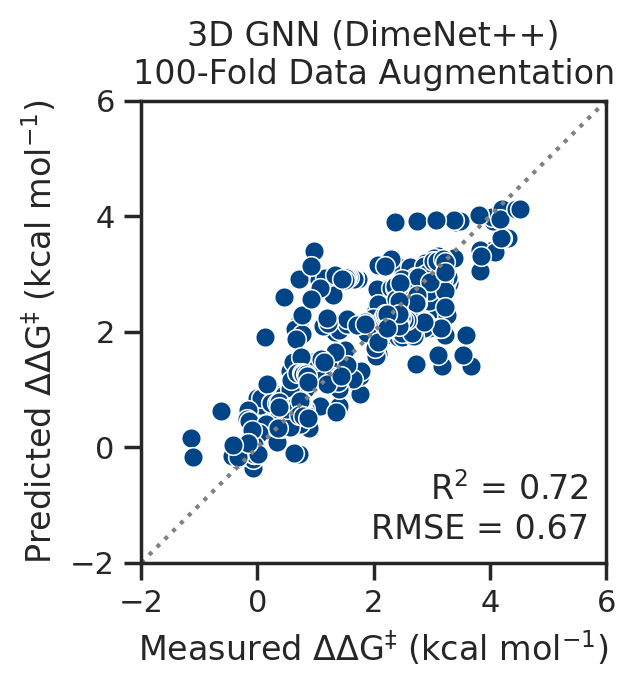

: 

In [ ]:
# Define colors and theme for the plot
colors = ["#004488", "#DDAA33", "#BB5566", "#000000"]
color = sns.color_palette(colors)
plt.rcParams.update({"figure.figsize": (3, 3)})
sns.set(rc={"figure.dpi": 200})
sns.set_theme(style="ticks", palette=color)
plt.tight_layout()

# Create scatter plot for literature (test) data
ax = sns.scatterplot(
    x=test_ddg,
    y=test_predictions,
    alpha=1,
    s=50,
    legend=False,
)


# Set axis labels
ax.set(
    xlabel=r"Measured $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
    ylabel=r"Predicted $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
)
# Set axis limits
ax.set_xlim(-2, 6)
ax.set_ylim(-2, 6)

# Add identity line (y=x) for reference
ax.plot(
    [0, 1],
    [0, 1],
    ":",
    color="grey",
    transform=ax.transAxes,
)
# Set plot title
ax.set_title("3D GNN (DimeNet++)\n100-Fold Data Augmentation")

# Add text box with performance metrics
ax.text(
    5.7,
    -1.7,
    f"R$^2$ = {loco_r2:0.2f}\nRMSE = {loco_rmse:0.2f}",
    fontsize=12,
    horizontalalignment="right",
    verticalalignment="bottom",
    # bbox=dict(facecolor="white", alpha=0.9),
)
